# SHIFT-SNARE: one-POI profiling and single-trace inference

This notebook demonstrates the analysis in a small, readable experiment: **`traces_per_class` profiling traces for intermediate 0 + the same number for intermediate −1 → one POI → two univariate Gaussian models → one unknown trace → predicted intermediate 0 or −1.**

## Leakage being exploited

Falcon's key-generation discrete Gaussian sampler compares random values with a threshold table to select a magnitude, then applies a sign. Bit extraction produces binary flags; negation expands a bit into a zero or all-ones mask. Their different Hamming weights can produce distinguishable power measurements even with a fixed instruction sequence.

| Leakage point | Sensitive expression | Role | Included |
|---|---|---|---|
| **AP1: magnitude-selection mask** | `-(t & (f ^ 1))` | Selects a table index through a mask whose classes are 0 and all ones (called −1 here). | **Yes: one POI.** |
| **AP2: sign mask** | `-neg` in `(v ^ -neg) + neg` | Applies the sampled sign through another zero/all-ones mask. | **No** |

Source context: [`mkgauss()` in Falcon's reference `keygen.c`](https://falcon-sign.info/impl/keygen.c.html). “−1” denotes the all-ones mask, including when the C type is unsigned; it is **not** the final sampled coefficient.

## Scope of this artifact

**Included:** load two CSV profiling files covering the **first five loop iterations**, generate labels from filenames, locate one candidate AP1 POI by absolute Pearson correlation, fit two Gaussians at that POI, and classify one new trace at the same sample.

**Not included:** a pipeline to identify and infer **all 54 POIs**, AP2/`neg` recovery, complete coefficient or secret-key reconstruction, automatic trace alignment, or automatic detection of loop boundaries. This is a single-POI demonstration of the larger attack.

Multiple loop operations may leak in the supplied window. We retain **one sample**, not one per loop. Filenames must label the AP1 mask at the targeted occurrence. If the two files encode different sequences of per-loop values, restrict the search to that occurrence with `search_start` and `search_stop`; a global correlation peak alone cannot determine which source instruction it belongs to.

## Setup with Python and pip

Use standard **Python 3.10 or newer** with pip and the standard `venv` module. Python 3.12 is a suitable baseline. Package availability also depends on your Python version and operating system; this is not a standalone executable. Setup needs internet access. On Linux distributions that package `venv` separately, install the matching Python venv support if environment creation reports that it is missing.

Put `requirements.txt`, this README, and the notebook in the same project folder. Open a terminal in that folder. The commands below explicitly call the environment's Python, so activation scripts and PowerShell execution-policy changes are unnecessary. Create a fresh `.venv` for this project rather than reusing an environment with the import error.

### Windows: PowerShell or Command Prompt

```text
python --version
python -m venv .venv
.\.venv\Scripts\python.exe -m pip install --upgrade pip
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
.\.venv\Scripts\python.exe -m pip check
.\.venv\Scripts\python.exe -m ipykernel install --user --name shift-snare --display-name "Python (SHIFT-SNARE)"
.\.venv\Scripts\python.exe -m jupyterlab
```

If Windows exposes Python as `py` rather than `python`, use `py` for the first two commands. The remaining commands stay the same.

### macOS or Linux

```bash
python3 --version
python3 -m venv .venv
.venv/bin/python -m pip install --upgrade pip
.venv/bin/python -m pip install -r requirements.txt
.venv/bin/python -m pip check
.venv/bin/python -m ipykernel install --user --name shift-snare --display-name "Python (SHIFT-SNARE)"
.venv/bin/python -m jupyterlab
```

Open the notebook and select **Python (SHIFT-SNARE)** as its kernel. In VS Code, choose the same kernel or the Python executable inside this project's `.venv`. Restart the kernel after switching, then run the environment-check cell before the analysis. That cell prints the executable and package versions and tests the imports. The executable path should point inside this project's `.venv`.

The direct dependencies are listed in `requirements.txt`. Pip selects compatible versions for the running Python. The ranges are not a complete version lock; record the installed versions with `python -m pip freeze` using the environment's Python when archiving a specific experiment.

## If NumPy/Matplotlib imports fail

`ImportError: numpy.core.multiarray failed to import` can indicate an incompatible compiled package or a damaged/mixed installation. Follow the fresh-environment setup above, then confirm the notebook uses that environment. Installing into one Python while running another kernel will not fix it. Do not install or downgrade packages in a running analysis kernel; stop it, install using the environment's Python, and restart. If the new environment still fails, retain the full traceback, printed Python path, and package versions for diagnosis.


### requirements.txt contents

Keep this file beside the notebook:

```text
# Python 3.10+ on Windows, macOS, or Linux. Install into a fresh venv.
# Windows: python -m venv .venv
# Windows: .\.venv\Scripts\python.exe -m pip install -r requirements.txt
# macOS/Linux: python3 -m venv .venv
# macOS/Linux: .venv/bin/python -m pip install -r requirements.txt
# See README.md for pip upgrade, kernel registration, and launch commands.
numpy>=1.26.4,<3
matplotlib>=3.9,<4
scipy>=1.13,<2
jupyterlab>=4.2,<5
ipykernel>=6.29,<8
```

## CSV inputs

**Actual profiling CSV layout:** rows are sample positions; column 0 is time in seconds; columns 1 onward are separate traces. The supplied files each contain 5,000 rows and 15,001 columns (15,000 traces plus time). Their time step is 4 ns. The loader excludes time, selects trace columns, then transposes to the analysis layout: traces × samples.

The old row-trimming script is unsuitable for these captures: taking the first 100 rows keeps only 100 sample positions. Use `keep_first_100_columns.py` to retain the time column and first 100 complete trace columns. This requires scanning all rows of a source file. It preserves the values and leaves the original file unchanged. If rows were already removed, recover the omitted time samples from the original CSV.

Extraction is optional: the loader can read selected trace columns directly from the original CSV. For the 100-trace copies, set `traces_per_class` to 100 or less and update the paths. No TRS conversion is performed.

Put the notebook beside a `data` folder with the reduced profiling files in `data/first100/` and the independent unknown trace in `data/`:

| File | Contents | Filename label |
|---|---|---|
| `first5_secret_0.csv` | At least `traces_per_class` trace columns; target AP1 mask is 0 | 0 |
| `first5_secret_-1.csv` | At least `traces_per_class` trace columns; target AP1 mask is −1 | −1 |
| `unknown.csv` | One separate, unknown trace of the same window | Not read as a label |

The prefix is arbitrary; the profiling filename must end in **`_0.csv` or `_-1.csv`**. Rename your files according to the known AP1 mask, not their `neg` flag. 

Use the same firmware, compiler settings, trigger alignment, sampling window, and scaling for profiling and inference. The unknown trace must be independent of the profiling traces. Run cells from top to bottom. Afterwards, change `unknown_file` and rerun only the configuration cell and inference cells to classify another trace with the same fitted models.

In [30]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Virtual environment:", sys.prefix != sys.base_prefix)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("SciPy:", scipy.__version__)
print("Imports successful. Confirm the executable is inside this project's .venv.")

Python executable: c:\Program Files\Python311\python.exe
Python version: 3.11.9
Virtual environment: False
NumPy: 2.2.6
Matplotlib: 3.10.7
SciPy: 1.16.3
Imports successful. Confirm the executable is inside this project's .venv.


## 1. Configuration

These are the settings to edit. By default, the search covers the whole supplied first-five-loop capture. If your files contain more of the execution, set the sample interval to the first five loops (or the particular AP1 occurrence). `search_stop` is exclusive. All indices are **zero-based**.

The CSV files are already converted. `sample_scale = 1.0` preserves their existing values; do not apply the TRS conversion factor a second time. Both profiling and unknown measurements must have the same scale.

The reduced files contain up to 100 traces each. We still use **50 per class** by default, matching the original experiment. Set `traces_per_class = 100` to use all 100 per class (200 profiling traces total). Loading stops after the requested number of rows; no full-file scan or conversion is performed.

In [31]:
profiling_files = [
    "./first100/first5_secret_0.csv",
    "./first100/first5_secret_-1.csv",
]
unknown_file = "./unknown.csv"
traces_per_class = 100
sample_scale = 1.0  # CSV values already have the conversion scaling.
search_start = 0
search_stop = None  # None searches to the end of the supplied capture.
samples_to_keep = 4500  # Preserves your latest crop; use None for all available samples.
unknown_columns_are_traces = True  # Unknown CSV was not supplied: confirm its layout.
# False: one trace per row, no time/index column.
# True: the same time-column + trace-columns format as the profiling files.


## 2. Load the profiling traces and generate labels

Select the first `traces_per_class` **columns after time**, keep the first `samples_to_keep` sample rows, then transpose. The returned array always has **one trace per row and one sample per column**. Filenames label each trace, not each time sample.

Your latest notebook crops to **4,500**, not 45,000 samples. This is retained. The supplied CSVs have only 5,000 sample rows, so they cannot supply a 45,000-sample window. No loop identity is inferred from the crop length alone.

In [32]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def load_traces(filename, count, columns_are_traces=True):
    with open(filename) as trace_file:
        if columns_are_traces:
            # Column 0 is time; select trace columns 1 through count.
            data = np.loadtxt(trace_file, delimiter=",", usecols=range(count +1),
                              max_rows=samples_to_keep, ndmin=2)
            time_seconds = data[:, 0]
            # if not np.isfinite(time_seconds).all() or not np.all(np.diff(time_seconds) > 0):
            #     raise ValueError(f"{filename}: column 0 must be increasing time values.")
            traces = data[:, 1:].T.copy()
        else:
            # Optional unknown-file layout: one trace per row, no time column.
            traces = np.loadtxt(trace_file, delimiter=",", max_rows=count, ndmin=2)
            traces = traces[:, :samples_to_keep]
    if traces.shape[0] != count:
        raise ValueError(f"{filename}: need {count} traces, found {traces.shape[0]}")
    if traces.shape[1] == 0 or not np.isfinite(traces).all():
        raise ValueError("Traces must contain finite samples of equal, nonzero length.")
    return traces * sample_scale

In [33]:
trace_groups = []
secret_labels = []

for filename in profiling_files:
    secret_value = int(Path(filename).stem.split("_")[-1])
    if secret_value not in [0, -1]:
        raise ValueError("Profiling filenames must end in _0.csv or _-1.csv.")
    group = load_traces(filename, traces_per_class)
    trace_groups.append(group)
    secret_labels.extend([secret_value] * traces_per_class)
    print(f"{Path(filename).name}: {group.shape[0]} traces × "
          f"{group.shape[1]} samples, intermediate = {secret_value}")

traces = np.concatenate(trace_groups, axis=0)
secret_labels = np.array(secret_labels)
assert len(profiling_files) == 2 and set(secret_labels) == {0, -1}
num_traces, num_samples = traces.shape
print(f"Combined measurements: {num_traces} traces × {num_samples} samples")

first5_secret_0.csv: 100 traces × 4500 samples, intermediate = 0
first5_secret_-1.csv: 100 traces × 4500 samples, intermediate = -1
Combined measurements: 200 traces × 4500 samples


### Inspect dimensions and the first traces

Print the **loaded dimensions: trace count × samples per trace**, then plot the first trace from each profiling file. These dimensions describe the selected rows, not the full source file. We do not scan a 163 GB file just to count its rows.

./first100/first5_secret_0.csv (loaded): 100 traces × 4500 samples per trace


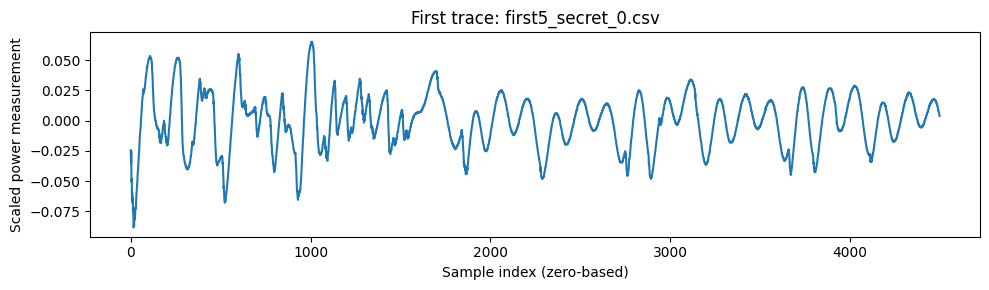

./first100/first5_secret_-1.csv (loaded): 100 traces × 4500 samples per trace


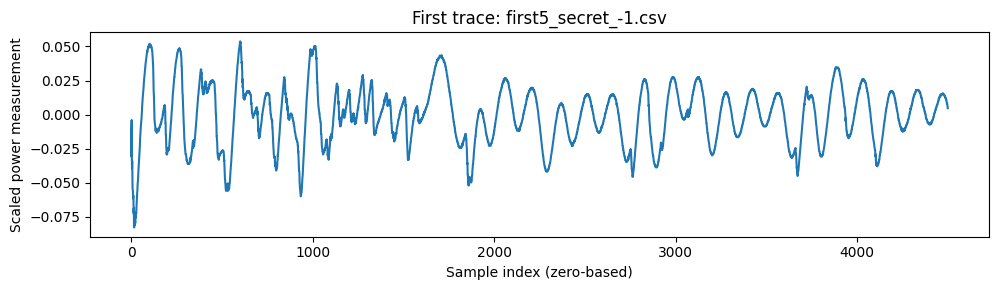

In [34]:
for filename, group in zip(profiling_files, trace_groups):
    trace_count, samples_per_trace = group.shape
    print(f"{filename} (loaded): {trace_count} traces × {samples_per_trace} samples per trace")

    plt.figure(figsize=(10, 3))
    plt.plot(group[0])
    plt.title(f"First trace: {Path(filename).name}")
    plt.xlabel("Sample index (zero-based)")
    plt.ylabel("Scaled power measurement")
    plt.tight_layout()
    plt.show()

The correlation labels are **pseudo-Hamming weights**, inherited from the original workflow: 0 for the zero mask and 64 for the all-ones mask. Their order follows the trace rows automatically, even if the file list is reversed. Using 0/1 or 0/32 would give the same Pearson correlation; 0/64 does not establish the actual register width of the compiled operation.

In [35]:
hw_labels = np.zeros(num_traces)
hw_labels[secret_labels == -1] = 64
print(f"HW 0 labels:  {np.sum(hw_labels == 0)}")
print(f"HW 64 labels: {np.sum(hw_labels == 64)}")

HW 0 labels:  100
HW 64 labels: 100


## 3. Find one point of interest

At each sample index $t$, correlate the profiling labels with the corresponding power measurements at that sample:

$$r(t)=\operatorname{corr}(\mathrm{HW\ labels},\ \mathrm{traces}[:,t]).$$

A large absolute correlation means the two labeled groups are well separated relative to their noise at that sample. The sign depends on the measurement polarity. We select the largest **absolute** correlation in the chosen interval; there is no key-guess loop.

In [36]:
stop = num_samples if search_stop is None else search_stop
assert 0 <= search_start < stop <= num_samples
correlations = np.full(num_samples, np.nan)

for sample_index in range(search_start, stop):
    sample_measurements = traces[:, sample_index]
    if np.std(sample_measurements) > 0:  # A constant column has undefined correlation.
        correlations[sample_index] = np.corrcoef(hw_labels, sample_measurements)[0, 1]

if not np.isfinite(correlations).any():
    raise ValueError("No varying samples in the selected search interval.")
poi = int(np.nanargmax(np.abs(correlations)))
print(f"Selected POI: sample {poi}")
print(f"Pearson correlation: {correlations[poi]:+.6f}")
print(f"Finite correlations: {np.isfinite(correlations).sum()} / {stop - search_start} searched samples")
print(f"Correlation range: {np.nanmin(correlations):+.6f} to {np.nanmax(correlations):+.6f}")


Selected POI: sample 3515
Pearson correlation: -0.931725
Finite correlations: 4500 / 4500 searched samples
Correlation range: -0.931725 to +0.868546


Second peak: sample 906, r=+0.861620


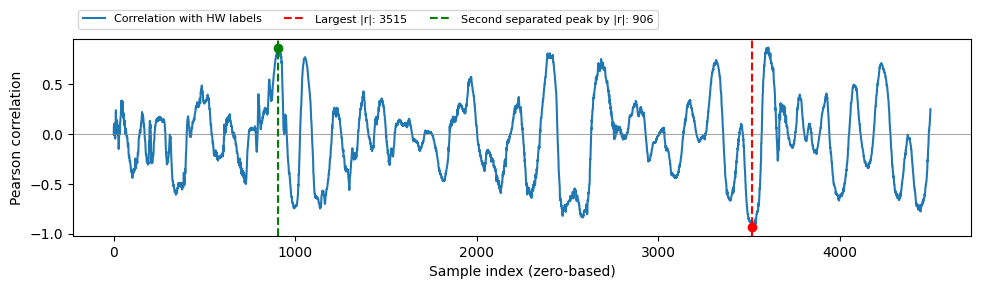

In [37]:
from scipy.signal import find_peaks

# Rank distinct local peaks by magnitude, including negative correlations.
peak_spacing = 100  # Adjustable separation in samples; not an inferred loop period.
strength = np.abs(np.nan_to_num(correlations, nan=0.0))
peaks, _ = find_peaks(strength, distance=peak_spacing)
# Include the selected global POI even if it is at an endpoint.
other_peaks = [int(p) for p in peaks if abs(int(p) - poi) >= peak_spacing]
second_peak = max(other_peaks, key=lambda p: strength[p]) if other_peaks else None

plt.figure(figsize=(10, 3))
plt.plot(correlations, label="Correlation with HW labels")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(poi, color="red", linestyle="--", label=f"Largest |r|: {poi}")
plt.scatter(poi, correlations[poi], color="red", zorder=3)
if second_peak is not None:
    plt.axvline(second_peak, color="green", linestyle="--",
                label=f"Second separated peak by |r|: {second_peak}")
    plt.scatter(second_peak, correlations[second_peak], color="green", zorder=3)
    print(f"Second peak: sample {second_peak}, r={correlations[second_peak]:+.6f}")
plt.xlabel("Sample index (zero-based)")
plt.ylabel("Pearson correlation")
# Automatic y limits show the actual data, including negative peaks.
plt.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

## 4. Build the two univariate Gaussian models

Extract only the selected sample from each profiling trace: `traces_per_class` measurements for mask 0 and the same number for mask −1. Estimate each class's mean and standard deviation and pass them to `norm(loc=..., scale=...)`. The standard deviation uses `ddof=0`, matching the original script.

These Gaussians model **measurement noise at the POI**; they are different from the discrete Gaussian distribution used by Falcon to sample secret coefficients. The histogram shows the actual profiling measurements so the Gaussian approximation can be inspected.

In [38]:
measurements_0 = traces[secret_labels == 0, poi]
measurements_minus1 = traces[secret_labels == -1, poi]

mean_0 = np.mean(measurements_0)
std_0 = np.std(measurements_0)
mean_minus1 = np.mean(measurements_minus1)
std_minus1 = np.std(measurements_minus1)
if std_0 == 0 or std_minus1 == 0:
    raise ValueError("A Gaussian model needs a nonzero standard deviation in each class.")

gaussian_0 = norm(loc=mean_0, scale=std_0)
gaussian_minus1 = norm(loc=mean_minus1, scale=std_minus1)
print(f"Intermediate  0: mean = {mean_0:.6g}, std = {std_0:.6g}")
print(f"Intermediate -1: mean = {mean_minus1:.6g}, std = {std_minus1:.6g}")

Intermediate  0: mean = 0.00163779, std = 0.000823435
Intermediate -1: mean = -0.00256702, std = 0.00081548


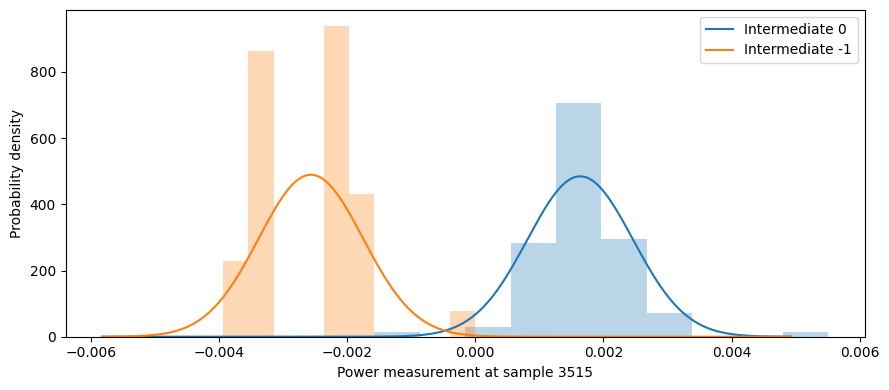

In [39]:
x_min = min(mean_0 - 4 * std_0, mean_minus1 - 4 * std_minus1)
x_max = max(mean_0 + 4 * std_0, mean_minus1 + 4 * std_minus1)
x = np.linspace(x_min, x_max, 500)

plt.figure(figsize=(9, 4))
plt.hist(measurements_0, bins=10, density=True, alpha=0.3, color="tab:blue")
plt.hist(measurements_minus1, bins=10, density=True, alpha=0.3, color="tab:orange")
plt.plot(x, gaussian_0.pdf(x), color="tab:blue", label="Intermediate 0")
plt.plot(x, gaussian_minus1.pdf(x), color="tab:orange", label="Intermediate -1")
plt.xlabel(f"Power measurement at sample {poi}")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Classify one unknown trace

Load one unknown trace and extract its sample at the **same POI**, without repeating POI selection or fitting. The unknown filename supplies no label. If the input contains multiple traces, this cell uses only the first.

Compare the two Gaussian log densities. Taking the logarithm preserves their ordering and avoids numerical underflow for very small densities. With equal class priors, the higher score gives the predicted intermediate; a tie is reported as undecided. The scores are not posterior probabilities.

Set `unknown_columns_are_traces` to match the unknown CSV. `False` means one trace per row with no time column; `True` means the profiling format with time in column 0. The unknown CSV was not attached, so its orientation has not been verified. The loader applies the same `samples_to_keep` crop before checking lengths.

Peak ranking alone does not assign a peak to an inner-loop iteration. The Gaussian fitting above still uses `poi`, the strongest absolute correlation. To model another verified operation, set `poi` to that sample and rerun fitting and inference.

./unknown.csv (loaded): 1 trace × 4500 samples per trace


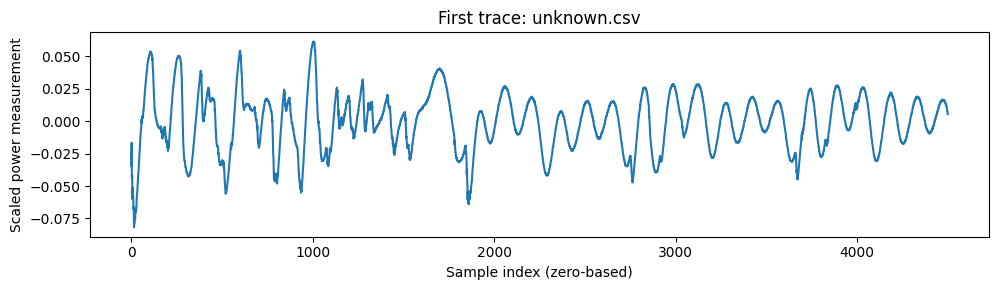

In [40]:
unknown_traces = load_traces(unknown_file, 1, columns_are_traces=True)
trace_count, samples_per_trace = unknown_traces.shape
print(f"{unknown_file} (loaded): {trace_count} trace × {samples_per_trace} samples per trace")
unknown_trace = unknown_traces[0]

plt.figure(figsize=(10, 3))
plt.plot(unknown_trace)
plt.title(f"First trace: {Path(unknown_file).name}")
plt.xlabel("Sample index (zero-based)")
plt.ylabel("Scaled power measurement")
plt.tight_layout()
plt.show()

In [41]:
if len(unknown_trace) != num_samples:
    raise ValueError("The unknown trace must use the same sampling window as profiling.")
measurement = unknown_trace[poi]
score_0 = gaussian_0.logpdf(measurement)
score_minus1 = gaussian_minus1.logpdf(measurement)

if score_0 > score_minus1:
    predicted_secret = 0
elif score_minus1 > score_0:
    predicted_secret = -1
else:
    predicted_secret = None

print(f"Unknown trace: {unknown_file}")
print(f"POI: {poi}; measurement: {measurement:.6g}")
print(f"Log density for  0: {score_0:.6f}")
print(f"Log density for -1: {score_minus1:.6f}")
print(f"Predicted AP1 intermediate: {predicted_secret}")

Unknown trace: ./unknown.csv
POI: 3515; measurement: -0.002362
Log density for  0: -5.614305
Log density for -1: 6.161191
Predicted AP1 intermediate: -1


## What the result means

The printed value is the estimated **0/−1 AP1 mask at one selected occurrence**. It is not the complete sampled coefficient, its sign, or the Falcon secret key. A peak shows association with the profiling labels; align it with the intended sampler operation before interpreting it as that operation's leakage.

Gaussian overlap, acquisition drift, or a misaligned trace can cause a wrong prediction. Use independent labeled test traces to measure accuracy; this notebook's single unknown prediction does not establish an attack success rate. Equal trace lengths do not guarantee alignment. Do not reuse the model after changing the firmware, sample window, or scaling without profiling again.

**Validation:** profiling was rerun against both CSVs in the supplied ZIP, with time excluded and trace columns transposed. Saved profiling outputs come from these captures. Unknown-trace inference is not run because no unknown CSV was provided. Restart the kernel and run from the top after changing the loader; old saved outputs can otherwise refer to different in-memory data.

With the supplied files and your settings (5,000 traces per class, first 4,500 samples), all 4,500 correlations are finite. The strongest absolute correlation is −0.919330 at sample 3515. With a 100-sample separation, the second peak by absolute correlation is −0.877645 at sample 2582. These ranks do not establish the source-code loop identity.
